# Numerical Exercises 3
## Exercise 03.1
### **Plain vanilla option pricing**

Black-Scholes theory assumes that the time evolution of the asset price is stochastic and exhibits geometric Brownian motion (GBM) with constant risk-free interest rate $r$ and volatility $\sigma$.

Black-Scholes **analytic solution** for the price at time t<T:
- European Call-option price:
$$ C\left[ S(t),t \right] = S(t) N(d_1) -K e^{-r(T-t)} N(d_2) $$
- European Put-option price:
$$ P\left[ S(t),t \right] = S(t) \left[ N(d_1)-1\right] -K e^{-r(T-t)} \left[ N(d_2)-1\right]$$

where 
$$d_1 = \frac{1}{\sigma\sqrt{T-t}}\left[ \ln \left( \frac{S(t)}{K} \right) + \left( r+\frac{\sigma^2}{2} (T-t) \right)\right]$$

where $d_2 = d_1 - \sigma\sqrt{T-t}$, and where
$$ N(x) = \int_{-\infty}^{x} dz \, e^{-\frac{z^2}{2}} = \frac{1}{2} \left[ 1+ {\rm erf} \left( \frac{x}{\sqrt{2}}\right) \right]$$
is the cumulative of Gaussian $\sim \mathcal{N}(\mu=0,\sigma^2=1)$,
and where
$${\rm erf}(x) = \frac{2}{\sqrt{\pi}}\int_{0}^{x} dz \, e^{-z^2}$$
By using the following parameters: 
- asset price at $t=0$: $S(0)=100$
- delivery time: $T=1$
- strike price: $K=100$
- risk-free interest rate: $r=0.1$
- volatility: $\sigma=0.25$

compute at time $t=0$ **via Monte Carlo** the European call-option price, $C[S(0),0]$, and put-option price, $P[S(0),0]$:
1. By sampling **directly** the final asset price $S(T)$ for a $GBM(r,\sigma^2)$
2. By sampling the discretized $GBM(r,\sigma^2)$ path of the asset price
dividing $[0,T]$ in $10^2$ time intervals: $S(0)$, $S(t_1)$, $S(t_2)$, ... up to $S(t_{100}=T=1)$
<p style="border:2px; border-style:solid; border-color:#F5F5F5; padding: 1em; background-color:#F5F5F5">
    Remember that given an asset price $S\sim GBM(\mu,\sigma^2)$, with initial value $S(0)$, then
    $$S(t) = S(0) \exp\left[ \left(\mu-\frac{1}{2}\sigma^2\right)t+\sigma W(t)\right]$$
    where $W(t)\sim\mathcal{N}(0,t)$.
    Moreover, since the increments of $W$ are independent and normally distributed, the simple recursive procedure for sampling discretized values of $S\sim GBM(\mu,\sigma^2)$ at $t_1 < t_2 < … < t_n$ is:
$$S(t_{i+1}) = S(t_i) \exp\left[ \left(\mu-\frac{1}{2}\sigma^2\right)(t_{i+1}-t_i)
    +\sigma Z_{i+1}\sqrt{t_{i+1}-t_i}\right]$$
    with $Z_i \sim \mathcal{N}(0,1)$
</p>

Make four pictures for the estimation of the European call-option prices, $C[S(0),0]$ (direct and discretized), and put-option prices, $P[S(0),0]$ (direct and discretized), with their uncertainties </span> with a large number of asset prices at time $t=T$, say $M\ge 10^4$, as a function of the number of blocks, $N$. As usual, in computing statistical uncertainties, use data blocking.</span>

### **Solution**
### European Options Pricing

An **option** is a financial contract granting the holder the *right*, but not the *obligation*, to trade an underlying asset at a specified strike price $K$ on an expiry date $T$. Only the writer is obligated to fulfill the contract if exercised. At maturity $t = T$, the payoff is determined by the final asset spot price $S(T)$:
* **Call option payoff**: $\max[0, S(T) - K]$
* **Put option payoff**: $\max[0, K - S(T)]$

Assuming a constant risk-free interest rate $r$, the fair price of an option at $t = 0$ corresponds to the expected value of the profit discounted by a factor $e^{-rT}$:
$$C[S(0), 0] = \left\langle e^{-rT} \max[0, S(T) - K] \right\rangle$$
$$P[S(0), 0] = \left\langle e^{-rT} \max[0, K - S(T)] \right\rangle$$

### Geometric Brownian Motion (GBM)

The Black-Scholes model assumes that the underlying asset price $S(t)$ follows a Geometric Brownian Motion governed by the stochastic differential equation:
$$dS(t) = r S(t) dt + \sigma S(t) dW(t)$$
where $\sigma$ is the volatility and $W(t)$ is a Wiener process characterized by $W(0) = 0$ and independent stationary normal increments $W(t) - W(s) \sim \mathcal{N}(0, t - s)$.

Given the initial spot price $S(0)$, the asset price is sampled via Monte Carlo through two different approaches:
* **Direct sampling**: the final price $S(T)$ is evaluated directly in a single step using $W(T) \sim \mathcal{N}(0, T)$:
  $$S(T) = S(0) \exp\left[ \left(r - \frac{1}{2}\sigma^2\right)T + \sigma W(T) \right]$$
* **Discretized (indirect) sampling**: the time window $[0, T]$ is divided into 100 equal sub-intervals with $\Delta t = T / 100$, updating the path recursively:
  $$S(t_{i+1}) = S(t_i) \exp\left[ \left(r - \frac{1}{2}\sigma^2\right)\Delta t + \sigma Z_{i+1}\sqrt{\Delta t} \right]$$
  where $Z_{i+1} \sim \mathcal{N}(0, 1)$ are independent standard normal variables.

### Implementation

The core logic of the numerical simulation is encapsulated within a custom `EuropeanOption` class. To maximize code reusability, this single class handles all four simulation scenarios through boolean flags (`is_call` and `is_discrete`), avoiding code duplication. 

Furthermore, computational performance is optimized by evaluating constant terms—such as the discount factor $e^{-rT}$ and the deterministic drift $r - \frac{1}{2}\sigma^2$ outside the main Monte Carlo loops. This simple expedient prevents millions of redundant and computationally expensive exponential function calls during the $10^5$ path evaluations.

The simulation is performed with the assigned parameters. Progressive averages and statistical uncertainties are evaluated using data blocking and compared to the analytical Black-Scholes prices: 
$$
\begin{aligned}
C &= 14.975790778311286 \\
P &= 5.4595325819072364
\end{aligned}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
blocks_c, _, c_val, c_err = np.loadtxt("OUTPUT/call.dat", unpack=True)
blocks_cd, _, cd_val, cd_err = np.loadtxt("OUTPUT/call_discr.dat", unpack=True)
blocks_p, _, p_val, p_err = np.loadtxt("OUTPUT/put.dat", unpack=True)
blocks_pd, _, pd_val, pd_err = np.loadtxt("OUTPUT/put_discr.dat", unpack=True)

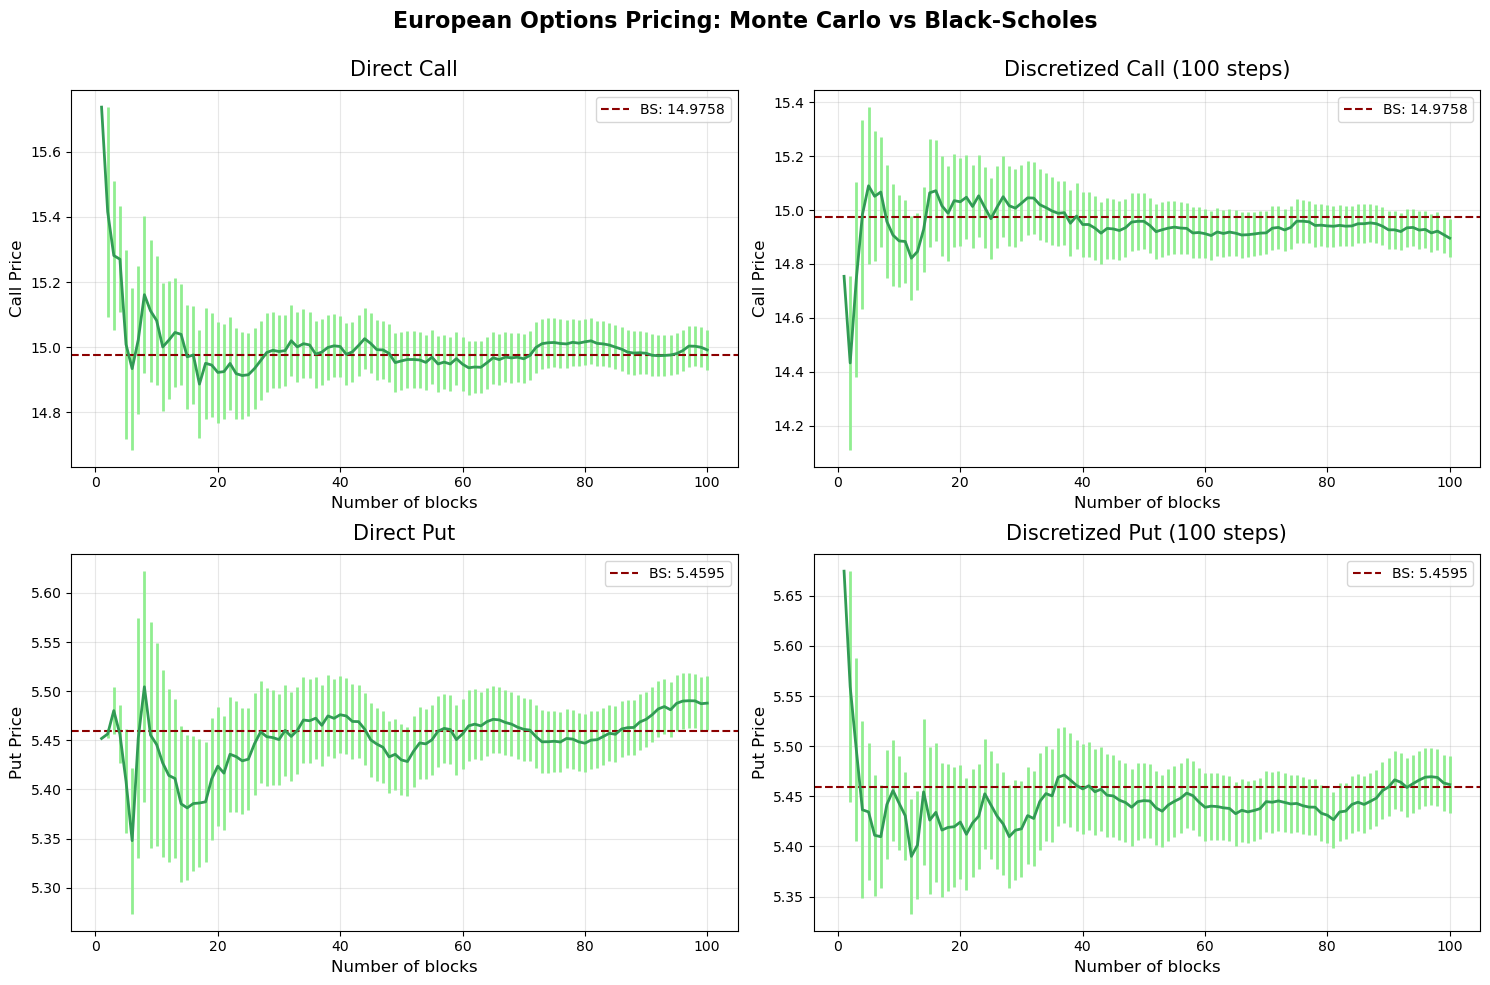

In [6]:
exact_call = 14.975790778311286
exact_put = 5.4595325819072364

fig, axs = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("European Options Pricing: Monte Carlo vs Black-Scholes", fontsize=16, fontweight='bold', y=0.98)

# --- 1. Call Diretta (Top-Left) ---
axs[0, 0].errorbar(blocks_c, c_val, yerr=c_err, fmt='-', color="#319B54", ecolor='lightgreen', elinewidth=2, linewidth=2)
axs[0, 0].set_title('Direct Call', fontsize=15, pad=10)
axs[0, 0].set_xlabel('Number of blocks', fontsize=12)
axs[0, 0].set_ylabel('Call Price', fontsize=12)
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].axhline(y=exact_call, color='darkred', linestyle='--', linewidth=1.5, label=f'BS: {exact_call:.4f}')
axs[0, 0].legend()

# --- 2. Call Discreta (Top-Right) ---
axs[0, 1].errorbar(blocks_cd, cd_val, yerr=cd_err, fmt='-', color="#319B54", ecolor='lightgreen', elinewidth=2, linewidth=2)
axs[0, 1].set_title('Discretized Call (100 steps)', fontsize=15, pad=10)
axs[0, 1].set_xlabel('Number of blocks', fontsize=12)
axs[0, 1].set_ylabel('Call Price', fontsize=12)
axs[0, 1].grid(True, alpha=0.3)
axs[0, 1].axhline(y=exact_call, color='darkred', linestyle='--', linewidth=1.5, label=f'BS: {exact_call:.4f}')
axs[0, 1].legend()

# --- 3. Put Diretta (Bottom-Left) ---
axs[1, 0].errorbar(blocks_p, p_val, yerr=p_err, fmt='-', color="#319B54", ecolor='lightgreen', elinewidth=2, linewidth=2)
axs[1, 0].set_title('Direct Put', fontsize=15, pad=10)
axs[1, 0].set_xlabel('Number of blocks', fontsize=12)
axs[1, 0].set_ylabel('Put Price', fontsize=12)
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].axhline(y=exact_put, color='darkred', linestyle='--', linewidth=1.5, label=f'BS: {exact_put:.4f}')
axs[1, 0].legend()

# --- 4. Put Discreta (Bottom-Right) ---
axs[1, 1].errorbar(blocks_pd, pd_val, yerr=pd_err, fmt='-', color="#319B54", ecolor='lightgreen', elinewidth=2, linewidth=2)
axs[1, 1].set_title('Discretized Put (100 steps)', fontsize=15, pad=10)
axs[1, 1].set_xlabel('Number of blocks', fontsize=12)
axs[1, 1].set_ylabel('Put Price', fontsize=12)
axs[1, 1].grid(True, alpha=0.3)
axs[1, 1].axhline(y=exact_put, color='darkred', linestyle='--', linewidth=1.5, label=f'BS: {exact_put:.4f}')
axs[1, 1].legend()

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

**Plot parameters**:
* $M = 10^5$ 
* $N = 10^2$
* $L = 10^3$

As shown in the plots, all four Monte Carlo simulations successfully converge to the theoretical Black-Scholes prices, represented by the red dashed lines. As the number of throws increases, the progressive averages stabilize and the statistical uncertainties gradually decrease, demonstrating the validity and the equivalence of both the direct and the discretized sampling approaches.